# Figure partitioning reanalysis uncertainty between impact model fitting and BCDS process

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import geopandas as gpd
from matplotlib import pyplot as plt
from matplotlib import patches as mpatches
from cartopy import crs as ccrs
import matplotlib as mpl
import cmocean
import seaborn as sns
import warnings
import string

import os
import glob
import re

from funcs_support import get_filepaths,get_params,utility_save,utility_print,load_shp
from funcs_plot import add_colorbar
dir_list = get_params()
dir_list['aux_bigmem'] = '/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/'

extra_fonts = {'lato':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Regular.ttf'),
 'lato-bold':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Bold.ttf')}

subplot_lettering = string.ascii_uppercase

In [2]:
from distributed import Client

# Start dask client 
client = Client()
display(client)

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 33927 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /node/crhtc70.hpc.ucar.edu/40728/proxy/33927/status,
Dashboard: /node/crhtc70.hpc.ucar.edu/40728/proxy/33927/status,Workers: 6
Total threads: 18,Total memory: 144.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:42077,Workers: 0
Dashboard: /node/crhtc70.hpc.ucar.edu/40728/proxy/33927/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:38501,Total threads: 3
Dashboard: /node/crhtc70.hpc.ucar.edu/40728/proxy/32959/status,Memory: 24.00 GiB
Nanny: tcp://127.0.0.1:41933,


2026-10-20 08:51:30,973 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 6b5eeacaf361db1499a06d1d54805eab initialized by task ('rechunk-merge-rechunk-transfer-e07a04f4d44f0ecdf52ff17e0c35678a', 0, 0, 0, 7, 0, 0, 0, 0, 0, 7, 0, 9) executed on worker tcp://127.0.0.1:35477
2026-10-20 08:51:33,314 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle f61dcef13b3b0a58e22e244440a79439 initialized by task ('rechunk-merge-rechunk-transfer-e07a04f4d44f0ecdf52ff17e0c35678a', 0, 0, 0, 6, 0, 0, 0, 0, 0, 6, 0, 9) executed on worker tcp://127.0.0.1:38213
2026-10-20 08:51:34,235 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 6b5eeacaf361db1499a06d1d54805eab deactivated due to stimulus 'task-finished-1792507894.2348285'
2026-10-20 08:51:36,158 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle bff97f47faeac3824580679d8c4b0994 initialized by task ('rechunk-merge-rechunk-transfer-e07a04f4d44f0ecdf52ff17e0c35678a', 0, 0, 0, 5, 0, 0, 0, 0, 0, 5, 0, 9) executed on wor

In [3]:
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','shp_fn':'impact-region','popwght':True},
               'gdppc':{'varname':'tasmeanpoly','geo_typ':'adm1','shp_fn':'country-fixed','popwght':True},
               'payroll':{'varname':'days90plus','geo_typ':'adm2-us','shp_fn':'UScounties','popwght':True}}



In [4]:
def load_impacts(proc,uncert_typ,return_maxgwl = False,return_crossfits=False,params_proc=params_proc):
    '''
    NOTE: MAX_GWL IS HARDCODED HERE
    '''
    
    # Load impacts projections
    if return_crossfits:
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}-cross*{'*popwght*'*params_proc[proc]['popwght']}.zarr'))
    else:
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_*{'*popwght*'*params_proc[proc]['popwght']}.zarr'))
    def load_impact(fn):
        ds_tmp = xr.open_zarr(fn,consolidated=False)
        ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
        ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})
    
        ds_tmp['exprun'] = ds_tmp['experiment']+ds_tmp['run']
        ds_tmp = ds_tmp.reset_index('idv')
        ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
        ds_tmp = ds_tmp.drop_vars(['flag_has_historical_duplicates','flag_resolution','flag_has_data','variable'],errors='ignore')
        return ds_tmp
    
    with warnings.catch_warnings():
        # Silence zarr warnings related to the /.done flags used
        warnings.filterwarnings('ignore')
        dss = xr.concat([load_impact(fn) for fn in fns],
                    dim='idv',join='outer')
    
    dss = dss.set_index({'poly_idx':'locid'}).rename({'poly_idx':'locid'})

    if return_maxgwl:
        return dss.maxgwl
    
    # Figure out how many BCD-ME members reach a given GWL
    gwl_counter = dss.maxgwl.load().reset_index('idv').groupby(['model','maxgwl']).count()
    gwl_counter = gwl_counter.sel(maxgwl = gwl_counter.maxgwl.values[::-1]).cumsum('maxgwl')
    #print(gwl_counter)
    
    dss_tmp = dss
    
    if 'noMERRA2' in uncert_typ:
        dss_tmp = dss_tmp.sel(proj_base = [pb for pb in dss_tmp.proj_base.values if pb != 'MERRA2'])
    
    if re.search(r'[0-9].*runs[0-9].*mods',uncert_typ):
        max_gwl = 3
        nruns = int(re.split('runs',uncert_typ)[0])
        
        gwlmods = gwl_counter.sel(maxgwl=max_gwl)
        proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values
        
        dss_tmp = dss_tmp.isel(idv = dss.maxgwl>=max_gwl).groupby('model').map(lambda x: x.isel(idv=slice(0, nruns)))
        dss_tmp = dss_tmp.isel(idv=[m in proc_mods for m in dss_tmp.model.values]).chunk({'idv':-1})

    for v in ['experiment','run']:
        dss_tmp[v] = dss_tmp[v].astype(object)
    dss_tmp = dss_tmp.unstack('idv')['d'+proc]
    #dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1})

    return dss_tmp

In [7]:
obsuncs_all = {}
overwrite = False
for proc in params_proc:
    tmp_fn1 = f'{dir_list['aux_bigmem']}crossfit_{proc}_rechk_tmp1.zarr'
    tmp_fn2 = f'{dir_list['aux_bigmem']}crossfit_{proc}_rechk_tmp2.zarr'
    if overwrite or (not os.path.exists(tmp_fn2)):
        dss = load_impacts(proc,'allruns',return_crossfits=True)
        dss = dss.chunk({'gwl':1,'fit_mod':-1,'proj_base':-1,'locid':5000})
        # Save rechunked as temporary file
        
        utility_save(dss,tmp_fn1,zarr_mode='w')
        dss = xr.open_zarr(tmp_fn1)
        dss = dss.chunk({'gwl':1,'fit_mod':-1,'proj_base':-1,'locid':200,'exprun':-1,'model':-1})
        
        utility_save(dss.drop_encoding(),tmp_fn2,zarr_mode='w')
        os.system('rm -rf '+tmp_fn1)
    dss = xr.open_zarr(tmp_fn2)

    fit_mods = ['ERA5','MERRA2','JRA-3Q','GMFD']


    obsuncs_all[proc] = xr.merge([dss.sel(fit_mod=fit_mods).mean('fit_mod').var('proj_base').mean('exprun').mean('model').compute().rename({'d'+proc:'bcds'}),
                                    dss.sel(fit_mod=fit_mods).var('fit_mod').mean('proj_base').mean('exprun').mean('model').compute().rename({'d'+proc:'impmod'}),
                                  dss.sel(fit_mod=fit_mods).mean('fit_mod').mean('proj_base').var('exprun').mean('model').compute().rename({'d'+proc:'uncint'}),
                                  dss.sel(fit_mod=fit_mods).mean('fit_mod').mean('proj_base').mean('exprun').var('model').compute().rename({'d'+proc:'uncmod'})],
                                   compat = 'no_conflicts')

In [8]:
indflag = 'noInd'
for proc in obsuncs_all:
    if proc == 'mortality':
        df_obsuncs = obsuncs_all[proc].sel(indflag = indflag).to_dataframe().reset_index().set_index(['gwl','locid']).sort_index()
    else:
        df_obsuncs = obsuncs_all[proc].to_dataframe().reset_index().set_index(['gwl','locid']).sort_index()
    df_tmp = np.log(df_obsuncs.loc[2][['impmod','bcds']])
    if proc == 'payroll':
        df_tmp = df_tmp.clip(lower = df_tmp.quantile(0.015),axis=1)
    print(df_tmp.corr())

          impmod      bcds
impmod  1.000000  0.456298
bcds    0.456298  1.000000
          impmod      bcds
impmod  1.000000  0.085475
bcds    0.085475  1.000000
          impmod      bcds
impmod  1.000000  0.467563
bcds    0.467563  1.000000


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/pandas/core/internals/blocks.py:347: RuntimeWarning: divide by zero encountered in log
  result = func(self.values, **kwargs)


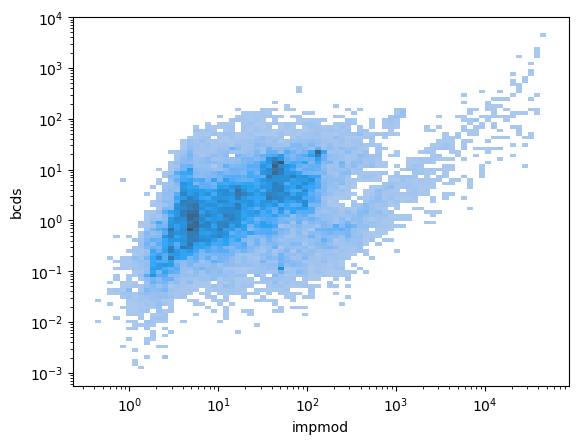

In [9]:
import seaborn as sns
import cmocean
proc = 'mortality'

ax = plt.subplot()
if proc == 'mortality':
    data_tmp = obsuncs_all[proc].sel(gwl=2,indflag='noInd')
else:
    data_tmp = obsuncs_all[proc].sel(gwl=2)
sns.histplot(data=data_tmp.to_dataframe(),
             x='impmod',y='bcds',ax=ax,log_scale=True)
plt.show()

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/pandas/core/internals/blocks.py:347: RuntimeWarning: divide by zero encountered in log
  result = func(self.values, **kwargs)


/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/Figure4.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/Figure4.png saved!


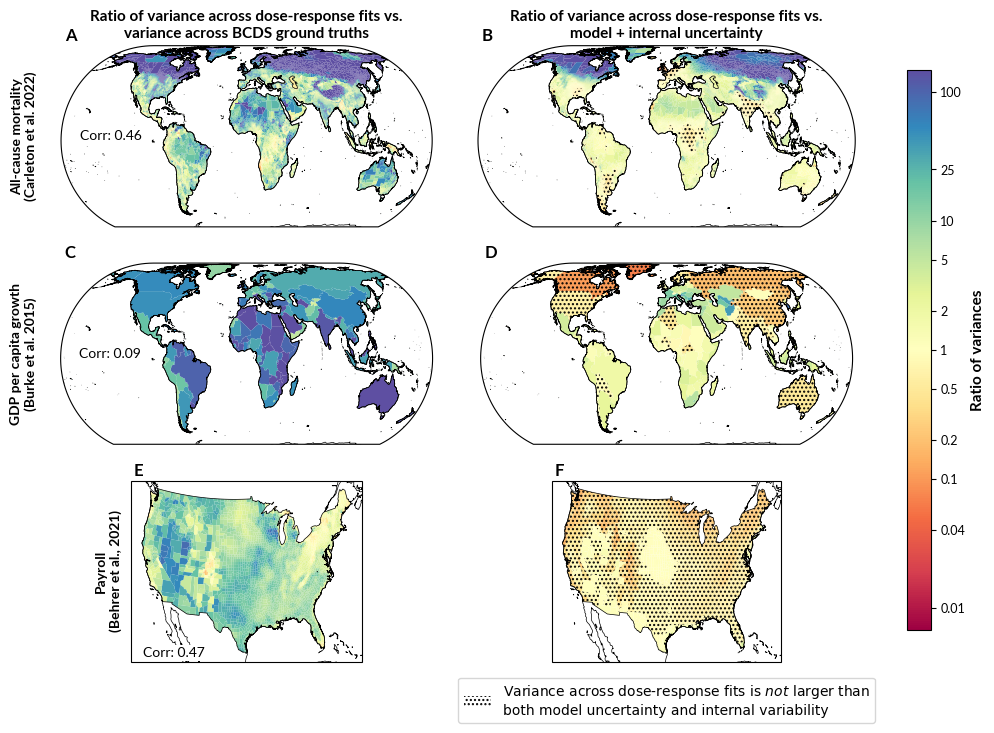

In [10]:
save_fig = True
output_fn = dir_list['figs']+'Figure4'

fig = plt.figure(figsize=(12,8))

gwl = 2

idxs = {'impact-regions':{'hierid':'locid'},
        'adm1':{'CNTRY_NAME':'locid'},
        'adm2-us':{'FIPS':'locid'}}

proc_full_names = {'mortality':'All-cause mortality\n(Carleton et al. 2022)',
                           'gdppc':'GDP per capita growth\n(Burke et al. 2015)',
                           'payroll':'Payroll\n(Behrer et al., 2021)'}

indflag = 'noInd'

cbar_params = {'cmap':'Spectral','vmin':-5,'vmax':5}

projs = {'mortality':ccrs.EckertIV(),
         'gdppc':ccrs.EckertIV(),
         'payroll':ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35)}

for row_idx,proc in enumerate(params_proc):
    # Load shapefile
    gdf = load_shp(proc)

    if proc == 'mortality':
        df_obsuncs = obsuncs_all[proc].sel(indflag = indflag).to_dataframe().reset_index().set_index(['gwl','locid']).sort_index()
    else:
        df_obsuncs = obsuncs_all[proc].to_dataframe().reset_index().set_index(['gwl','locid']).sort_index()

    # Get correlation between BCDS and Impact Model reanalysis uncertainty
    df_tmp = np.log(df_obsuncs.loc[2][['impmod','bcds']])
    if proc == 'payroll':
        # Drop the long tail of 0 or nearly 0 change locations for payroll
        df_tmp = df_tmp.clip(lower = df_tmp.quantile(0.015),axis=1)
    corr = np.round(df_tmp.corr().loc['impmod','bcds'],2)
    corrstr = 'Corr: '+str(corr)
        
    ratio_to_bcds = np.log(df_obsuncs.loc[gwl]['impmod'] / df_obsuncs.loc[gwl]['bcds'])
    ratio_to_bcds.name= 'impmod_to_bcds'
    ratio_to_intmod = np.log(df_obsuncs.loc[gwl]['impmod'] / (df_obsuncs.loc[gwl]['uncint'] + 
                                                                         df_obsuncs.loc[gwl]['uncmod']))
    ratio_to_intmod.name= 'impmod_to_intmod'
    
    ratios = pd.merge(ratio_to_bcds,ratio_to_intmod,left_index=True,right_index=True)
    ratios.index = ratios.index.set_names(list(idxs[params_proc[proc]['geo_typ']].values())[0])

    gdf = gdf.join(ratios,on=list(idxs[params_proc[proc]['geo_typ']].values())[0])

    #----- Plot of ratio of model training to BCDS
    ax = plt.subplot(3,2,2*row_idx+1,projection=projs[proc])

    # Plot 
    gdf.plot(column='impmod_to_bcds',**cbar_params,
            ax=ax,transform=ccrs.PlateCarree())
    gdf.dissolve().plot(facecolor='none',edgecolor='k',ax=ax,transform=ccrs.PlateCarree(),
                        linewidth=0.5)
    ax.coastlines(linewidth=0.5)

    if row_idx == 0:
        ax.set_title('Ratio of variance across dose-response fits vs.\nvariance across BCDS ground truths',
                     font = extra_fonts['lato-bold'],fontsize=11)
    else:
        ax.set_title('')

    # Correlation label
    bbox_params = {'facecolor':'w','edgecolor':'none','pad':1.5}
    if proc == 'payroll':
        corrpos = (0.05,0.05)
    else:
        corrpos = (0.05,0.5)
    ax.annotate(corrstr,
                corrpos,ha='left',va='center',
                xycoords = 'axes fraction',
                bbox = bbox_params,
                font=extra_fonts['lato'])

    # Row labels
    ax.annotate(proc_full_names[proc],
                (-0.1,0.5),xycoords = 'axes fraction',
                fontweight='bold',fontsize=10,va='center',ha='center',
                rotation=90,font=extra_fonts['lato-bold'])
    # Subplot label
    ax.annotate(subplot_lettering[row_idx*2],(0.01,1.01),xycoords = 'axes fraction',
                            fontweight='bold',fontsize=12,va='bottom',font=extra_fonts['lato-bold'])

    #----- Plot of ratio of model training to mod + int
    ax = plt.subplot(3,2,2*row_idx+2,projection=projs[proc])

    # Plot
    gdf.plot(column='impmod_to_intmod',**cbar_params,
            ax=ax,transform=ccrs.PlateCarree())
    gdf.dissolve().plot(facecolor='none',edgecolor='k',ax=ax,transform=ccrs.PlateCarree(),
                        linewidth=0.5)

    # Add hatching to areas where impmod is _not_ larger than both uncint or uncmod
    imp_largest_source = (df_obsuncs['impmod'] > df_obsuncs['uncint']) & (df_obsuncs['impmod'] > df_obsuncs['uncmod'])
    gdf.set_index('locid').where(~imp_largest_source.loc[gwl]).dropna(how='all').dissolve().plot(hatch='....',facecolor='none',linewidth=0,
                                                                                        transform=ccrs.PlateCarree(),
                                                                                        ax=ax)
    
    ax.coastlines(linewidth=0.5)


    if row_idx == 0:
        ax.set_title('Ratio of variance across dose-response fits vs.\nmodel + internal uncertainty',
                    font = extra_fonts['lato-bold'],fontsize=11)
    else:
        ax.set_title('')

    if row_idx == len(params_proc)-1:
        ax.legend(handles=[mpatches.Patch(facecolor='none', edgecolor='k', linewidth=0,
                                          hatch='....', 
                                          label=r'Variance across dose-response fits is $\it{not}$ larger than'+'\nboth model uncertainty and internal variability')],
                bbox_to_anchor = [0.5,-0.05],loc='upper center')
    # Subplot label
    ax.annotate(subplot_lettering[row_idx*2+1],(0.01,1.01),xycoords = 'axes fraction',
                            fontweight='bold',fontsize=12,va='bottom',font=extra_fonts['lato-bold'])

# Vertical colorbar
fig.subplots_adjust(right=0.825,wspace=0)
cbar = add_colorbar(cbar_params,orientation='vertical',fig=fig,
                    axpos = [0.85, 0.15, 0.02, 0.7])
ticklocs = [1/100,1/25,1/10,1/5,1/2,1,2,5,10,25,100]
cbar.set_ticks([np.log(k) for k in ticklocs],
               labels=[str(k) for k in ticklocs],
               font = extra_fonts['lato'],
               fontsize=9)
cbar.set_label('Ratio of variances',font = extra_fonts['lato-bold'],fontsize=11)

if save_fig:
    utility_print(output_fn)
    

In [13]:
import xagg as xa
for proc in obsuncs_all:
    print(f'\n*** {proc} ***')
    # Get sum of model and internal 
    obsuncs_all[proc]['intmod'] = obsuncs_all[proc]['uncint'] + obsuncs_all[proc]['uncmod']

    # Get whether the uncertainty from the impact model
    # is by itself larger than that from the internal
    # and model uncertainties together
    impmod_greaterthan_intmod = (obsuncs_all[proc]['impmod'] > obsuncs_all[proc]['intmod']).sel(gwl=2).to_dataframe(name='impmod_dom')[['impmod_dom']]
    gdf = load_shp(proc).set_index('locid')
    gdf = gdf.join(impmod_greaterthan_intmod)
    # Reproj into WGS84 for area calcs
    gdf = gdf.to_crs('EPSG:4087')
    
    
    # Get relative area of globe for each
    gdf_areas = gdf.dissolve(by='impmod_dom').area
    print('-- by area')
    print(str(np.round((gdf.impmod_dom*gdf.area).sum()/gdf.area.sum(),2)))
    print(str(gdf_areas / gdf_areas.sum()))
    
    # Now, get by population
    if proc == 'mortality':
        preds = xr.open_zarr(dir_list['proc']+'aux/all_preds.zarr')
        pop = preds[['pop']].sel(gwl=0.61,ageset='agetotal',pred_ssp='ssp3',pred_model='high')
        pop = pop.mean('year').load()
    
        gdf = gdf.join(pop.rename({'hierid':'locid'}).to_dataframe()['pop'])
    
        gdf_pops = gdf.groupby('impmod_dom')['pop'].sum()
    elif proc == 'gdppc':
        gdf_pops = gdf.groupby('impmod_dom')['POP_CNTRY'].sum() 
        gdf = gdf.rename({'POP_CNTRY':'pop'},axis=1)
    elif proc == 'payroll':
        # Load population by grid cell
        pop_fn = dir_list['aux']+'pop_data/pop_fx_LANDSCAN_conus_day_025deg_2016.nc'
        pop = xr.open_dataset(pop_fn)
    
        with xa.set_options(silent=True):
            wm = xa.pixel_overlaps(pop,gdf.to_crs('EPSG:4326'))
            with xa.set_options(impl='numba'):
                agg = xa.aggregate(pop,wm)
                agg_out = agg.to_dataset()
        
        agg_out['locid'] = agg_out['STATE_FIPS']+agg_out['CNTY_FIPS']
        gdf = gdf.join(agg_out.to_dataframe().set_index('locid')['pop'])
        gdf['pop'] = (gdf.to_crs('EPSG:4087').geometry.area*gdf['pop'])
        gdf_pops = gdf.groupby('impmod_dom')['pop'].sum()
    print('\n-- by pop')
    print(str(np.round((gdf['impmod_dom']*gdf['pop']).sum()/gdf['pop'].sum(),2)))
    print(str(gdf_pops / gdf_pops.sum()))


*** mortality ***
-- by area
0.92
impmod_dom
False    0.112005
True     0.887995
dtype: float64

-- by pop
0.76
impmod_dom
False    0.238333
True     0.761667
Name: pop, dtype: float64

*** gdppc ***
-- by area
0.38
impmod_dom
False    0.6222
True     0.3778
dtype: float64

-- by pop
0.43
impmod_dom
False    0.565366
True     0.434634
Name: POP_CNTRY, dtype: float64

*** payroll ***
-- by area
0.09
impmod_dom
False    0.908158
True     0.091842
dtype: float64

-- by pop
0.07
impmod_dom
False    0.926505
True     0.073495
Name: pop, dtype: float64
